In [0]:
%pip install rapidfuzz 'mlxtend<0.24' fastapi uvicorn nest_asyncio streamlit 'scipy<1.14' 'torch>=2.3.0'
dbutils.library.restartPython()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 37.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 58.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.5/10.5 MB 149.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 33.4/33.4 MB 171.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 454.0/454.0 MB 132.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 651.0/651.0 MB 112.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 221.1/221.1 MB 109.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.0/216.0 MB 105.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.2/60.2 MB 84.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 542.8/542.8 MB 81.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 73.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.0/43.0 MB 90.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 

In [0]:
import re
import os
import warnings
from collections import Counter
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from rapidfuzz import fuzz, process


warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
pd.set_option('future.no_silent_downcasting', True)

plt.style.use('seaborn-v0_8-muted')
sns.set_theme(style='whitegrid')

print('✅ Imports e configurações carregados com sucesso.')

✅ Imports e configurações carregados com sucesso.


In [0]:


def carregar_e_auditar_dados():
    tabelas_alvo = ['TAB_VENDA_ITEM', 'TAB_VENDA', 'TAB_PRODUTO']
    datasets_finais = {}
    
    # 📌 Configuração do Catálogo onde os dados foram salvos
    catalog_name = "workspace"
    schema_name = "default"

    print('=' * 80)
    print(f"📋 ESCOPO DA ANÁLISE: {', '.join(tabelas_alvo)}")
    print('=' * 80)

    for tabela in tabelas_alvo:
        print(f'\n▶️  PROCESSANDO: {tabela}')
        tabela_virtual = f"{catalog_name}.{schema_name}.{tabela.lower()}"
        
        try:
            # Consome a tabela virtualizada e converte para Pandas
            df = spark.table(tabela_virtual).toPandas()
            # Converte nomes de colunas para minúsculo
            df.columns = [col.lower() for col in df.columns]
            
            colunas_originais = list(df.columns)
            print(f'   📊 Campos identificados: {len(colunas_originais)}')

            # Limpa nulos textuais
            df = df.replace(r'^\s*$', np.nan, regex=True).replace('None', np.nan).replace('nan', np.nan)
            total_rows = len(df)

            campos_integros = []
            campos_para_remover = []

            for col in colunas_originais:
                nulos = df[col].isnull().sum()
                distintos = df[col].nunique()

                if nulos == 0:
                    campos_integros.append(col)

                if nulos == total_rows:
                    campos_para_remover.append((col, '100% Nulo'))
                elif distintos <= 1:
                    val = df[col].dropna().unique() if distintos == 1 else 'Vazio'
                    campos_para_remover.append((col, f"Constante ('{val}') — sem variância"))

            print(f'   ✅ Campos 100% preenchidos: {len(campos_integros)}')

            if campos_para_remover:
                print('   ❌ Campos removidos:')
                for col_rem, motivo in campos_para_remover:
                    print(f'      - {col_rem}: {motivo}')
            else:
                print('   ✨ Nenhum campo removido.')

            # Remove colunas desnecessárias
            cols_remover = [c for c, _ in campos_para_remover]
            df_final = df.drop(columns=cols_remover)
            datasets_finais[tabela] = df_final

            print(f'   📄 Resultado: {len(df_final.columns)} colunas × {total_rows} linhas.')

        except Exception as e:
            print(f'   💥 Erro ao carregar ou processar a tabela {tabela_virtual}: {e}')

    return datasets_finais

# Executa a auditoria apenas nos dados já virtualizados
datasets = carregar_e_auditar_dados()

📋 ESCOPO DA ANÁLISE: TAB_VENDA_ITEM, TAB_VENDA, TAB_PRODUTO

▶️  PROCESSANDO: TAB_VENDA_ITEM
   📊 Campos identificados: 46
   ✅ Campos 100% preenchidos: 15
   ❌ Campos removidos:
      - rec: 100% Nulo
      - id_filial: 100% Nulo
      - cor_id: 100% Nulo
      - tabela: 100% Nulo
      - grade_id: 100% Nulo
      - vendedor_id: 100% Nulo
      - obs: 100% Nulo
      - altura: 100% Nulo
      - largura: 100% Nulo
      - altlar: 100% Nulo
      - locacao_dt_ini: 100% Nulo
      - locacao_dt_fin: 100% Nulo
      - locacao_dt_prova: 100% Nulo
      - locacao_status: 100% Nulo
      - sinal: 100% Nulo
      - entrega_id: 100% Nulo
      - tx_comissao: 100% Nulo
      - endereco_ordem: 100% Nulo
      - romaneio: 100% Nulo
      - impresso: 100% Nulo
      - qtd_devolvida: 100% Nulo
      - id_filial_ult_alt: 100% Nulo
      - servico_item: 100% Nulo
      - vlr_comissao: 100% Nulo
      - id_web: 100% Nulo
      - sincronizado: 100% Nulo
      - ordem: 100% Nulo
      - dthr_recebeu_entr

📊 EDA — ANÁLISE EXPLORATÓRIA DE DADOS

📈 FATURAMENTO:
   Ticket Médio : R$ 45.82
   Valor Máximo : R$ 2478.70


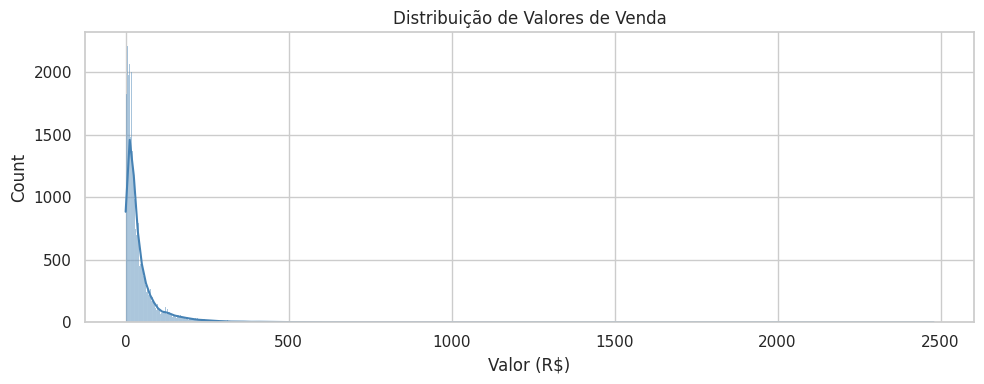

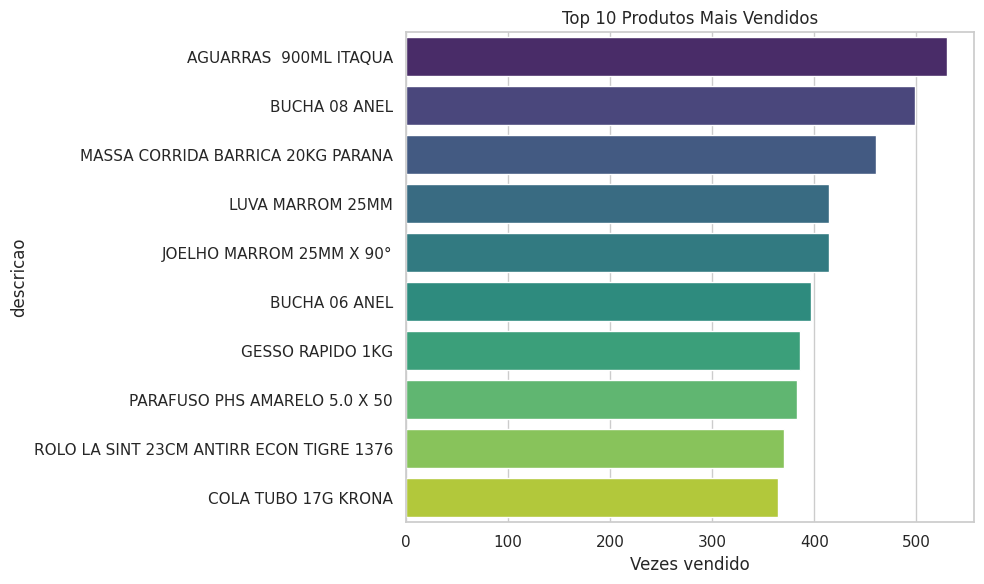


🛒 Média de itens por cupom: 2.08


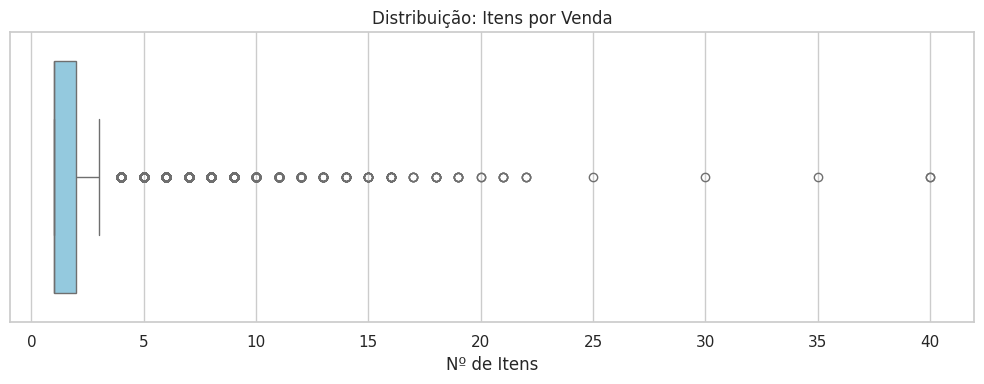

In [0]:
# ============================================================
# CÉLULA 4 — EDA GERAL (FATURAMENTO, PRODUTOS, CESTAS)
# ============================================================

def executar_eda_completa(datasets):
    print('=' * 80)
    print('📊 EDA — ANÁLISE EXPLORATÓRIA DE DADOS')
    print('=' * 80)

    # 1. Faturamento
    if 'TAB_VENDA' in datasets:
        df_v = datasets['TAB_VENDA'].copy()
        col_valor = 'ven_cur_subtotal'
        df_v[col_valor] = pd.to_numeric(df_v[col_valor], errors='coerce')

        print(f'\n📈 FATURAMENTO:')
        print(f'   Ticket Médio : R$ {df_v[col_valor].mean():.2f}')
        print(f'   Valor Máximo : R$ {df_v[col_valor].max():.2f}')

        plt.figure(figsize=(10, 4))
        sns.histplot(df_v[col_valor].dropna(), kde=True, color='steelblue')
        plt.title('Distribuição de Valores de Venda')
        plt.xlabel('Valor (R$)')
        plt.tight_layout()
        plt.show()

    # 2. Top produtos
    if 'TAB_VENDA_ITEM' in datasets:
        df_i = datasets['TAB_VENDA_ITEM']
        top_produtos = df_i['descricao'].value_counts().head(10)

        plt.figure(figsize=(10, 6))
        sns.barplot(x=top_produtos.values, y=top_produtos.index, palette='viridis')
        plt.title('Top 10 Produtos Mais Vendidos')
        plt.xlabel('Vezes vendido')
        plt.tight_layout()
        plt.show()

    # 3. Densidade de cesta
    if 'TAB_VENDA_ITEM' in datasets:
        itens_venda = df_i.groupby('ven_id').size()
        print(f'\n🛒 Média de itens por cupom: {itens_venda.mean():.2f}')

        plt.figure(figsize=(10, 4))
        sns.boxplot(x=itens_venda, color='skyblue')
        plt.title('Distribuição: Itens por Venda')
        plt.xlabel('Nº de Itens')
        plt.tight_layout()
        plt.show()

    # 4. Correlação numérica
    if 'TAB_VENDA_ITEM' in datasets:
        df_num = df_i.select_dtypes(include=['float64', 'int64'])
        if not df_num.empty:
            plt.figure(figsize=(8, 6))
            sns.heatmap(df_num.corr(), annot=True, cmap='coolwarm', fmt='.2f')
            plt.title('Matriz de Correlação')
            plt.tight_layout()
            plt.show()


executar_eda_completa(datasets)

🔢 MÉTRICAS ESTATÍSTICAS — TAB_VENDA
   Contagem      : 31543
   Faturamento   : R$ 1445181.92
   Ticket Médio  : R$ 45.82
   Mediana       : R$ 22.60
   Desvio Padrão : R$ 78.84
   Mínimo        : R$ 0.00
   Máximo        : R$ 2478.70


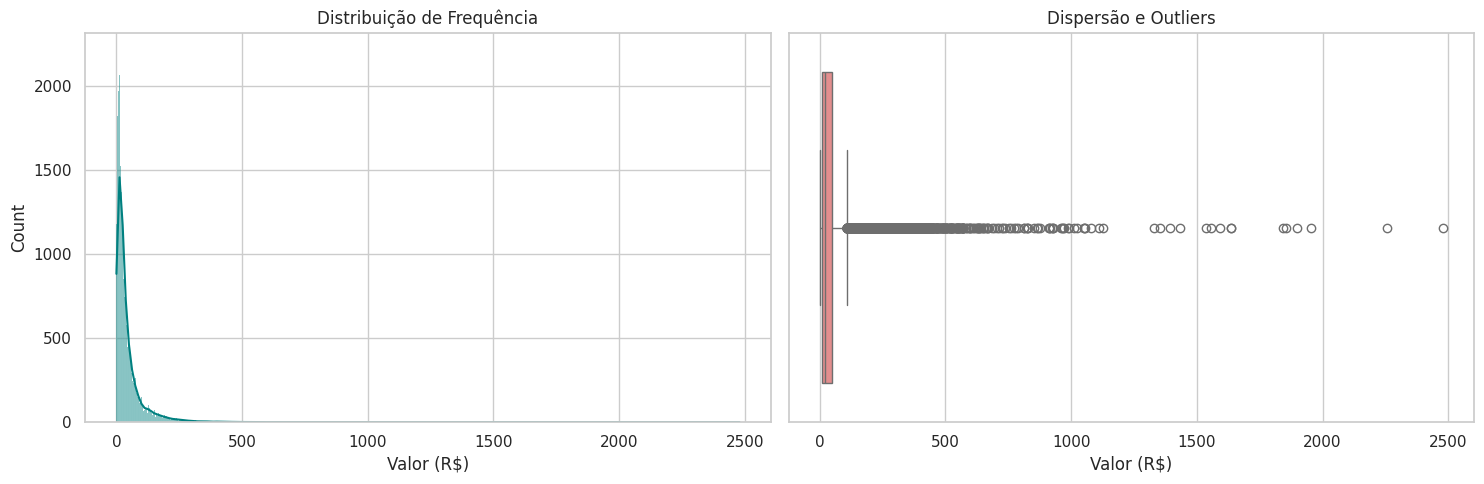

In [0]:
# ============================================================
# CÉLULA 5 — EDA DETALHADO DE VENDAS
# ============================================================

def eda_detalhado_vendas(datasets):
    if 'TAB_VENDA' not in datasets:
        print('❌ Dataset TAB_VENDA não encontrado.')
        return

    df = datasets['TAB_VENDA'].copy()
    col_valor = 'ven_cur_subtotal'
    df[col_valor] = pd.to_numeric(df[col_valor], errors='coerce')

    print('=' * 60)
    print('🔢 MÉTRICAS ESTATÍSTICAS — TAB_VENDA')
    print('=' * 60)
    s = df[col_valor].describe()
    print(f"   Contagem      : {int(s['count'])}")
    print(f"   Faturamento   : R$ {df[col_valor].sum():.2f}")
    print(f"   Ticket Médio  : R$ {s['mean']:.2f}")
    print(f"   Mediana       : R$ {df[col_valor].median():.2f}")
    print(f"   Desvio Padrão : R$ {s['std']:.2f}")
    print(f"   Mínimo        : R$ {s['min']:.2f}")
    print(f"   Máximo        : R$ {s['max']:.2f}")

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))
    sns.histplot(df[col_valor].dropna(), kde=True, color='teal', ax=ax1)
    ax1.set_title('Distribuição de Frequência')
    ax1.set_xlabel('Valor (R$)')

    sns.boxplot(x=df[col_valor].dropna(), color='lightcoral', ax=ax2)
    ax2.set_title('Dispersão e Outliers')
    ax2.set_xlabel('Valor (R$)')

    plt.tight_layout()
    plt.show()


eda_detalhado_vendas(datasets)

In [0]:
# ============================================================
# CÉLULA 6 — SANEAMENTO: REMOÇÃO DE VENDAS ZERADAS
# ============================================================

def filtrar_vendas_invalidas(datasets):
    if 'TAB_VENDA' not in datasets:
        print('❌ TAB_VENDA não encontrada.')
        return datasets

    df_vendas = datasets['TAB_VENDA'].copy()
    col_valor  = 'ven_cur_subtotal'
    df_vendas[col_valor] = pd.to_numeric(df_vendas[col_valor], errors='coerce')

    total_original = len(df_vendas)
    df_limpo = df_vendas[
        (df_vendas[col_valor] > 0) & df_vendas[col_valor].notna()
    ]
    total_atual  = len(df_limpo)
    qtd_excluida = total_original - total_atual
    pct          = (qtd_excluida / total_original) * 100

    datasets['TAB_VENDA'] = df_limpo

    print('=' * 60)
    print('🛡️  SANEAMENTO: VENDAS ZERADAS')
    print('=' * 60)
    print(f'   Registros originais  : {total_original}')
    print(f'   Excluídos (valor≤0)  : {qtd_excluida} ({pct:.2f}%)')
    print(f'   Dataset válido       : {total_atual} registros')

    return datasets


datasets = filtrar_vendas_invalidas(datasets)

🛡️  SANEAMENTO: VENDAS ZERADAS
   Registros originais  : 31543
   Excluídos (valor≤0)  : 294 (0.93%)
   Dataset válido       : 31249 registros


🧠 EDA: ANÁLISE DE AFINIDADE PARA RECOMENDAÇÃO
   Itens antes            : 65490
   Itens após saneamento  : 64858
   Excluídos              : 632 (0.97%)
--------------------------------------------------------------------------------
📊 Esparsidade da matriz : 99.9550%
🛒 Média de itens/venda  : 1.99


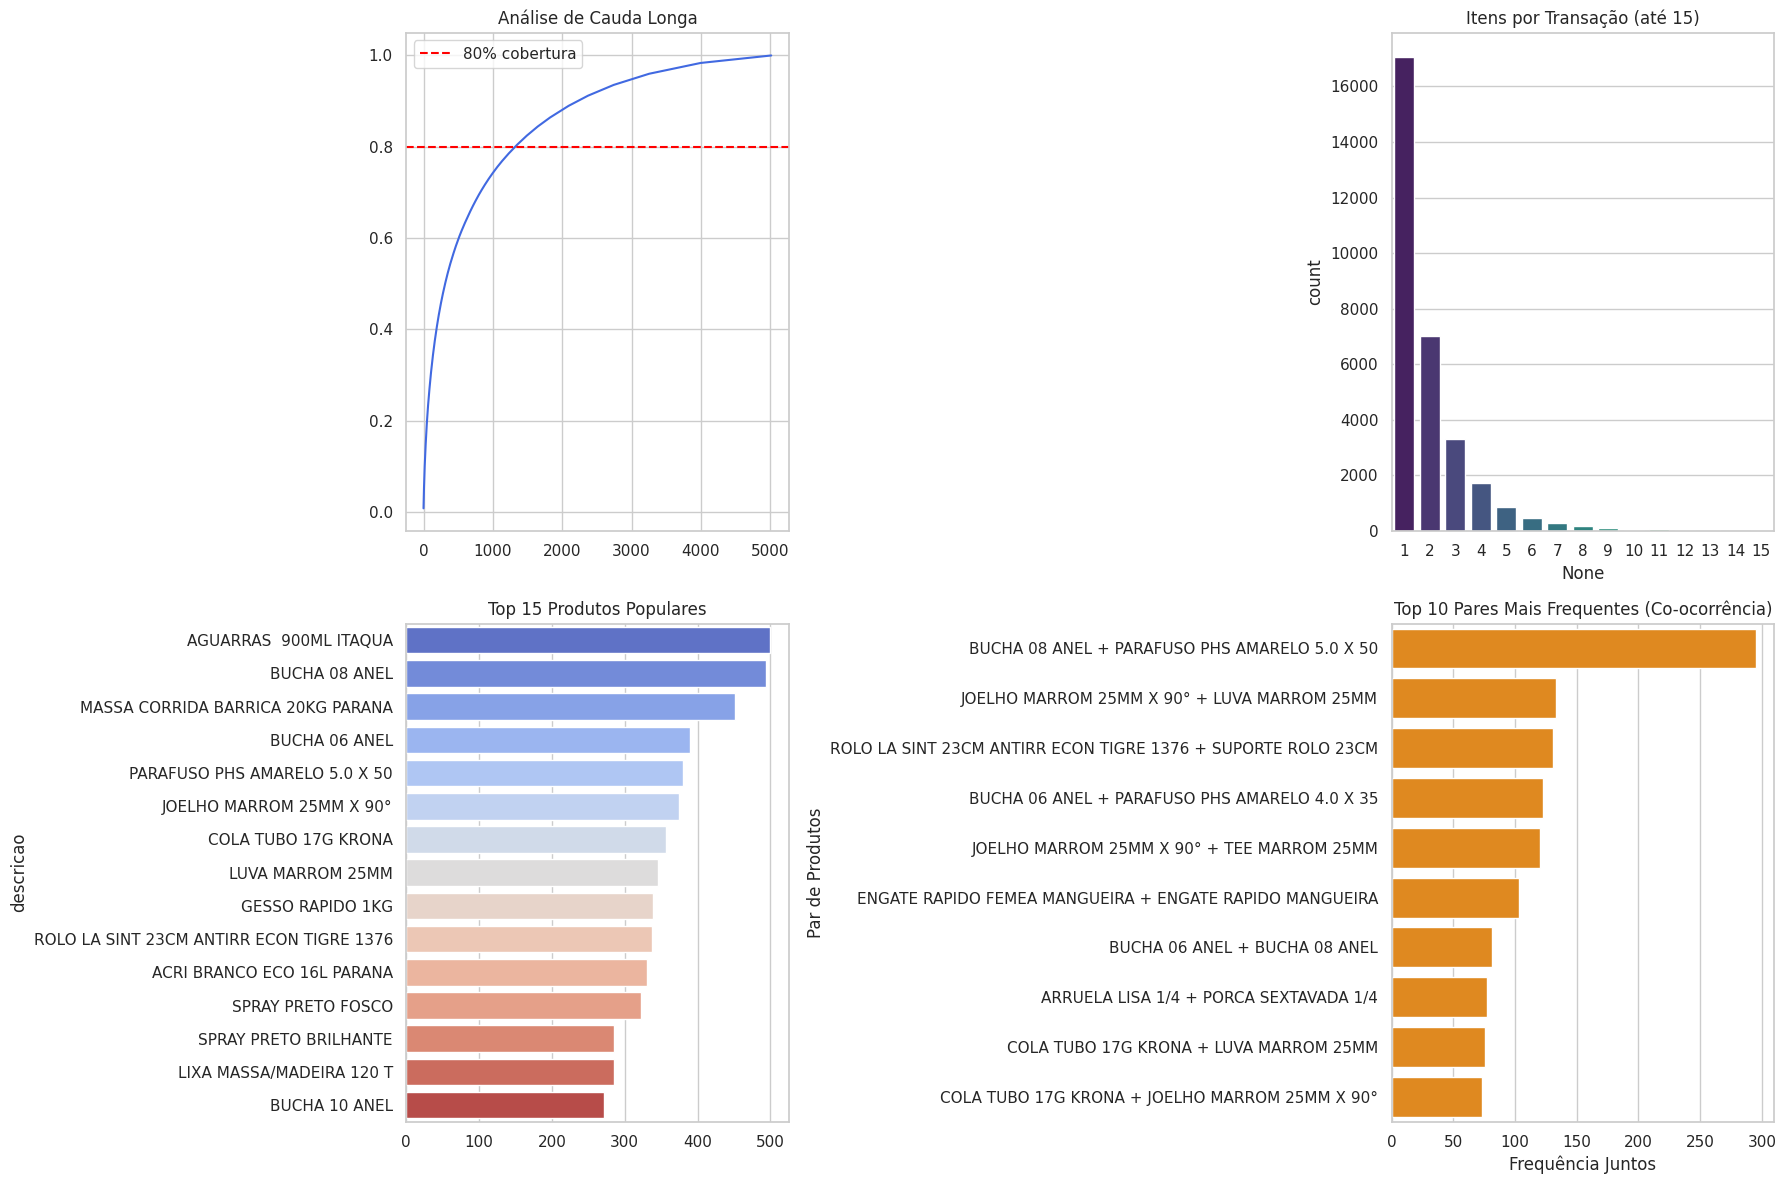

In [0]:
# ============================================================
# CÉLULA 7 — EDA PARA RECOMENDAÇÃO (AFINIDADE E CO-OCORRÊNCIA)
# ============================================================

def eda_recomendacao_venda_item(datasets):
    if 'TAB_VENDA_ITEM' not in datasets or 'TAB_VENDA' not in datasets:
        print('❌ Tabelas necessárias ausentes.')
        return datasets

    df_vendas   = datasets['TAB_VENDA']
    df_itens_raw = datasets['TAB_VENDA_ITEM']

    total_antes = len(df_itens_raw)
    df = df_itens_raw[df_itens_raw['ven_id'].isin(df_vendas['ven_id'])].copy()
    total_depois = len(df)
    qtd_excluida = total_antes - total_depois
    pct = (qtd_excluida / total_antes) * 100 if total_antes > 0 else 0

    df_presenca = df.drop_duplicates(subset=['ven_id', 'pro_id'])

    print('=' * 80)
    print('🧠 EDA: ANÁLISE DE AFINIDADE PARA RECOMENDAÇÃO')
    print('=' * 80)
    print(f'   Itens antes            : {total_antes}')
    print(f'   Itens após saneamento  : {total_depois}')
    print(f'   Excluídos              : {qtd_excluida} ({pct:.2f}%)')
    print('-' * 80)

    n_vendas = df['ven_id'].nunique()
    n_itens  = df['pro_id'].nunique()
    esparsidade = 0
    if n_vendas > 0 and n_itens > 0:
        esparsidade = (1 - len(df_presenca) / (n_vendas * n_itens)) * 100

    cesta_size = df_presenca.groupby('ven_id').size()

    print(f'📊 Esparsidade da matriz : {esparsidade:.4f}%')
    print(f'🛒 Média de itens/venda  : {cesta_size.mean():.2f}')

    # Top pares de co-ocorrência
    vendas_agrupadas = df_presenca.groupby('ven_id')['descricao'].apply(list)
    pares = Counter()
    for itens in vendas_agrupadas:
        if len(itens) > 1:
            pares.update(combinations(sorted(itens), 2))

    top_pares_data = [
        {'Par de Produtos': f'{p1} + {p2}', 'Frequência Juntos': freq}
        for (p1, p2), freq in pares.most_common(10)
    ]
    top_pares = pd.DataFrame(top_pares_data)

    fig, ax = plt.subplots(2, 2, figsize=(18, 12))

    item_counts = df_presenca['descricao'].value_counts(normalize=True).cumsum()
    ax[0, 0].plot(range(len(item_counts)), item_counts.values, color='royalblue')
    ax[0, 0].axhline(y=0.8, color='red', linestyle='--', label='80% cobertura')
    ax[0, 0].set_title('Análise de Cauda Longa')
    ax[0, 0].legend()

    sns.countplot(x=cesta_size.clip(upper=15), ax=ax[0, 1], palette='viridis')
    ax[0, 1].set_title('Itens por Transação (até 15)')

    top_15 = df_presenca['descricao'].value_counts().head(15)
    sns.barplot(x=top_15.values, y=top_15.index, ax=ax[1, 0], palette='coolwarm')
    ax[1, 0].set_title('Top 15 Produtos Populares')

    if not top_pares.empty:
        sns.barplot(
            data=top_pares, x='Frequência Juntos', y='Par de Produtos',
            ax=ax[1, 1], color='darkorange'
        )
        ax[1, 1].set_title('Top 10 Pares Mais Frequentes (Co-ocorrência)')

    plt.tight_layout()
    plt.show()

    datasets['TAB_VENDA_ITEM'] = df
    return datasets


datasets = eda_recomendacao_venda_item(datasets)

📝 ANÁLISE SEMÂNTICA — pro_txt_descricao
   Produtos únicos        : 18936
   Padrões 3-gram repetidos: 1945


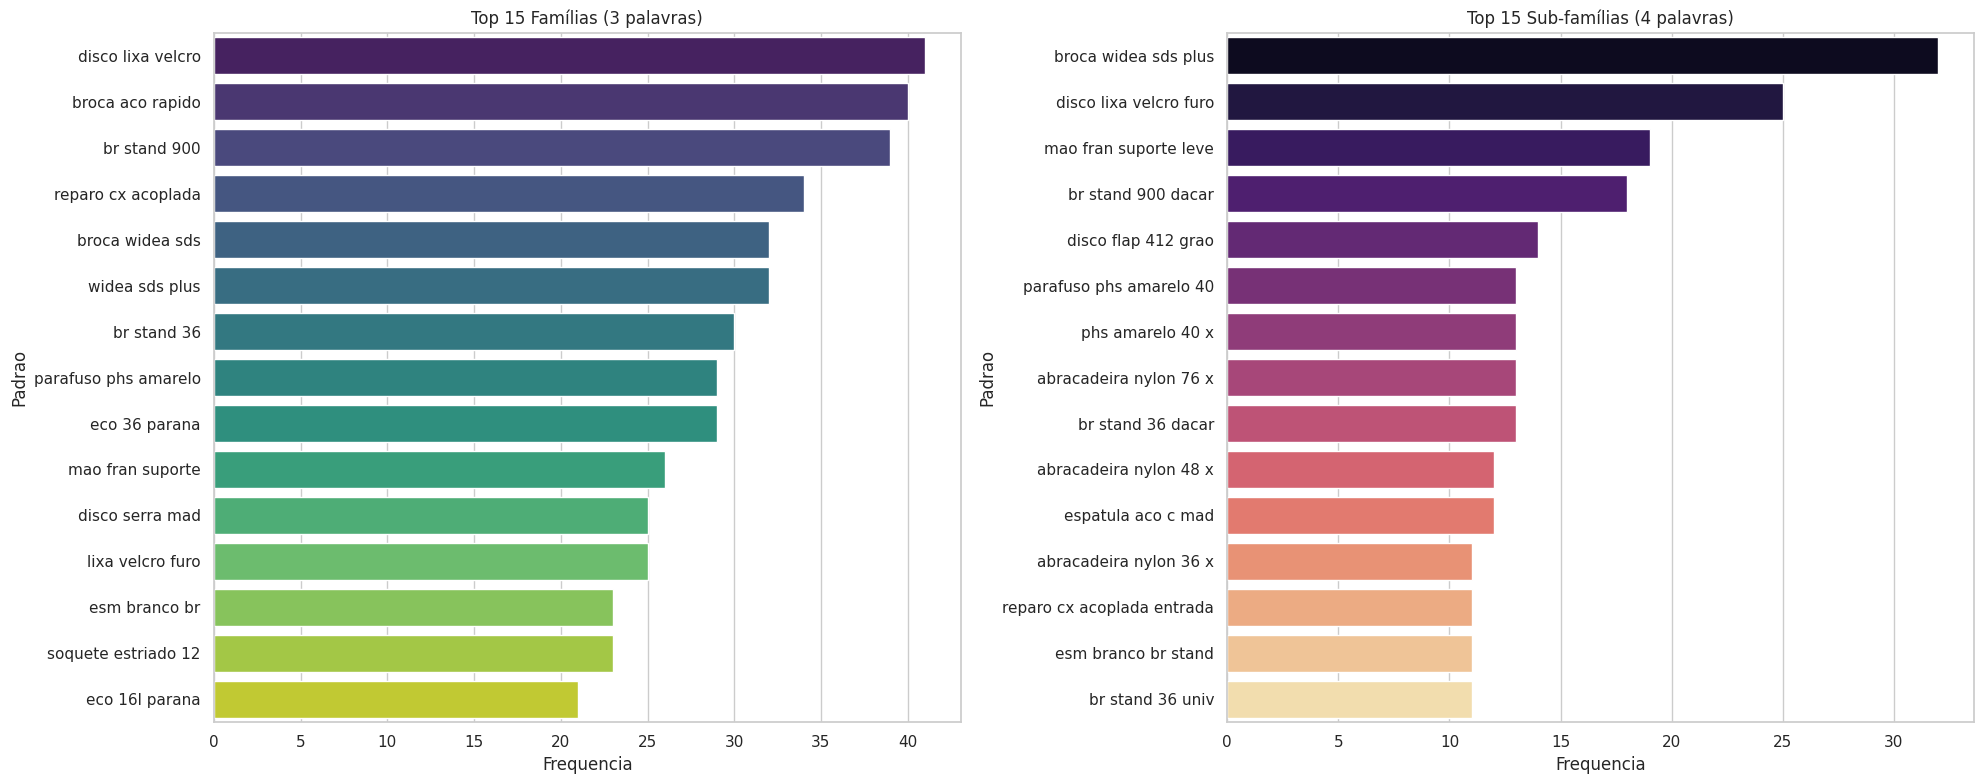


🔍 CLUSTERS POR PREFIXO (>= 3 variações):
   📦 [00]: 20 variações
      Exemplos: ['00"', '00"', '00"']
   📦 [00 ROGE11]: 10 variações
      Exemplos: ['00 roge11', '00 roge11', '00 roge11']
   📦 [00SOROCABA]: 13 variações
      Exemplos: ['00sorocaba "', '00sorocaba "', '00sorocaba "']
   📦 [01]: 9 variações
      Exemplos: ['01"', '01"', '01"']
   📦 [02]: 26 variações
      Exemplos: ['02"', '02"', '02"']
   📦 [03]: 9 variações
      Exemplos: ['03"', '03"', '03"']
   📦 [04FORT]: 6 variações
      Exemplos: ['04fort"', '04fort"', '04fort"']
   📦 [07]: 5 variações
      Exemplos: ['07"', '07"', '07"']
   📦 [07FERA]: 20 variações
      Exemplos: ['07fera"', '07fera"', '07fera"']
   📦 [11PREM]: 6 variações
      Exemplos: ['11prem"', '11prem"', '11prem"']
   📦 [13]: 3 variações
      Exemplos: ['13"', '13"', '13"']
   📦 [14TAMB]: 7 variações
      Exemplos: ['14tamb"', '14tamb"', '14tamb"']
   📦 [15]: 4 variações
      Exemplos: ['15"', '15"', '15"']
   📦 [17]: 29 variações
      Exempl

In [0]:
# ============================================================
# CÉLULA 8 — ANÁLISE SEMÂNTICA / NLP DE DESCRIÇÕES
# ============================================================

def eda_robustez_textual(datasets):
    if 'TAB_PRODUTO' not in datasets:
        print('❌ TAB_PRODUTO não encontrada.')
        return datasets

    df_p     = datasets['TAB_PRODUTO'].copy()
    col_desc = 'pro_txt_descricao'

    def limpar_texto(txt):
        txt = str(txt).lower()
        txt = re.sub(r'[^\w\s]', '', txt)
        return txt.strip()

    def extrair_ngramas(txt, n):
        palavras = txt.split()
        if len(palavras) < n:
            return []
        return [' '.join(palavras[i:i+n]) for i in range(len(palavras) - n + 1)]

    df_p['desc_clean'] = df_p[col_desc].apply(limpar_texto)

    ngrams_3, ngrams_4 = [], []
    for d in df_p['desc_clean']:
        ngrams_3.extend(extrair_ngramas(d, 3))
        ngrams_4.extend(extrair_ngramas(d, 4))

    df_ng3 = pd.DataFrame(Counter(ngrams_3).most_common(15), columns=['Padrao', 'Frequencia'])
    df_ng4 = pd.DataFrame(Counter(ngrams_4).most_common(15), columns=['Padrao', 'Frequencia'])

    print('=' * 80)
    print(f'📝 ANÁLISE SEMÂNTICA — {col_desc}')
    print('=' * 80)
    print(f'   Produtos únicos        : {len(df_p)}')
    print(f'   Padrões 3-gram repetidos: {len([k for k, v in Counter(ngrams_3).items() if v > 1])}')

    fig, ax = plt.subplots(1, 2, figsize=(20, 8))
    sns.barplot(data=df_ng3, x='Frequencia', y='Padrao', palette='viridis', ax=ax[0])
    ax[0].set_title('Top 15 Famílias (3 palavras)')
    sns.barplot(data=df_ng4, x='Frequencia', y='Padrao', palette='magma', ax=ax[1])
    ax[1].set_title('Top 15 Sub-famílias (4 palavras)')
    plt.tight_layout()
    plt.show()

    print('\n🔍 CLUSTERS POR PREFIXO (>= 3 variações):')
    df_p['prefixo_3'] = df_p['desc_clean'].apply(lambda x: ' '.join(x.split()[:3]))
    grupos = df_p.groupby('prefixo_3')[col_desc].apply(list)
    for prefixo, lista in grupos.items():
        if len(lista) >= 3:
            print(f'   📦 [{prefixo.upper()}]: {len(lista)} variações')
            print(f'      Exemplos: {lista[:3]}')

    return datasets


datasets = eda_robustez_textual(datasets)

In [0]:
# ============================================================
# CÉLULA 9 — DIAGNÓSTICO DE THRESHOLD (MÉTODO DO COTOVELO)
# ============================================================
import re
import pandas as pd
from rapidfuzz import process, fuzz

def diagnosticar_threshold(datasets, amostra=6000, score_min=70, score_max=95):
    if 'TAB_PRODUTO' not in datasets:
        print('❌ TAB_PRODUTO não encontrada.')
        return

    df_p = datasets['TAB_PRODUTO'].copy()

    def extrair_mestre_bruto(txt):
        txt = str(txt).upper()
        
        # 1. Remove frações de polegada (ex: 1/2, 3/4, 1.1/2, 2 1/4)
        txt = re.sub(r'\d+[\.,]?\d*\s*/\s*\d+', ' ', txt)
        
        # 2. Remove dimensões com X (ex: 50X60, 4 X 2, 5.0x45, 12X12)
        txt = re.sub(r'\d+[\.,]?\d*\s*X\s*\d+[\.,]?\d*', ' ', txt)
        
        # 3. Remove palavras que contêm qualquer número grudado (ex: 25MM, 110V, P120, C64)
        txt = re.sub(r'\b[A-Z]*\d+[A-Z]*\b', ' ', txt)
        
        # 4. Remove unidades órfãs (todas as medidas, potências e embalagens)
        # Se algum "MM" ou "VOLT" ficar solto após tirar o número, ele morre aqui.
        unidades = (
            r'\b(MM|MILIMETRO|MILIMETROS|CM|CENTIMETRO|CENTIMETROS|M|METRO|METROS|'
            r'G|GR|GRAMA|GRAMAS|KG|KILO|KILOS|QUILO|QUILOS|QUILOGRAMA|QUILOGRAMAS|'
            r'L|LT|LITRO|LITROS|ML|MILILITRO|MILILITROS|POL|POLEGADA|POLEGADAS|'
            r'V|VOLT|VOLTS|W|WATT|WATTS|A|AMPERE|AMPERES|UN|UNID|UNIDADE|UNIDADES|'
            r'PC|PÇ|PCA|PÇA|PECA|PECAS|CX|CAIXA|CAIXAS|PCT|PACOTE|PACOTES|'
            r'JG|JOGO|PAR|PARES|KIT|FR|FRASCO|ROLO|ROLOS|BD|BALDE)\b'
        )
        txt = re.sub(unidades, ' ', txt)
        
        # 5. Remove pontuações e traços (ex: -, ., ())
        txt = re.sub(r'[^\w\s]', ' ', txt)
        
        # Divide as palavras e limpa espaços vazios
        palavras = txt.split()
        
        # Retorna as 3 primeiras palavras 
        return ' '.join(palavras[:3]) if len(palavras) >= 3 else ' '.join(palavras)

    mestres = df_p['pro_txt_descricao'].apply(extrair_mestre_bruto).unique().tolist()
    amostra_mestres = mestres[:amostra]

    print('=' * 70)
    print(f'🔬 DIAGNÓSTICO DE THRESHOLD (scores entre {score_min} e {score_max})')
    print(f'   Analisando {len(amostra_mestres)} mestres (amostra de {len(mestres)} únicos)')
    print('=' * 70)

    pares_zona_cinzenta = []
    vistos = set()

    for mestre in amostra_mestres:
        hits = process.extract(
            mestre,
            amostra_mestres,
            scorer=fuzz.token_sort_ratio,
            score_cutoff=score_min,
            limit=10
        )
        for h_txt, h_score, _ in hits:
            if h_txt == mestre:
                continue
            chave = tuple(sorted([mestre, h_txt]))
            if chave in vistos:
                continue
            vistos.add(chave)
            if score_min <= h_score <= score_max:
                pares_zona_cinzenta.append((h_score, mestre, h_txt))

    pares_zona_cinzenta.sort(reverse=True)

    if not pares_zona_cinzenta:
        print('   ✅ Nenhum par ambíguo encontrado na faixa especificada.')
        return

    # --- LÓGICA DO MÉTODO DO COTOVELO (ELBOW METHOD / KNEEDLE ALGORITHM) ---
    thresholds_teste = list(range(score_max, score_min - 1, -1))
    pares_acumulados = []
    
    # 1. Acumula quantos pares existem para cada nível de threshold
    for t in thresholds_teste:
        qtd = sum(1 for score, a, b in pares_zona_cinzenta if score >= t)
        pares_acumulados.append(qtd)
        
    N_min = min(pares_acumulados)
    N_max = max(pares_acumulados)
    
    melhor_threshold = 82
    maior_distancia = -1
    
    # 2. Calcula a distância ortogonal normalizada para achar a inflexão
    if N_max > N_min:
        for i, t in enumerate(thresholds_teste):
            # x varia de 0 (threshold 95) até 1 (threshold 70)
            x = (score_max - t) / (score_max - score_min)
            # y varia de 0 (mínimo de pares) até 1 (máximo de pares)
            y = (pares_acumulados[i] - N_min) / (N_max - N_min)
            
            # Distância até a reta base (y = x)
            dist = x - y 
            
            if dist > maior_distancia:
                maior_distancia = dist
                melhor_threshold = t

    melhor_threshold = max(75, min(melhor_threshold, 95))

    # --- IMPRESSÃO DOS RESULTADOS ---
    print(f'\n   {len(pares_zona_cinzenta)} pares na zona cinzenta encontrados (top 15 exibidos):\n')
    print(f'   {"Score":>5}  {"Mestre A":<35}  {"Mestre B"}')
    print('   ' + '-' * 80)
    for score, a, b in pares_zona_cinzenta[:15]:  
        print(f'   {score:>5.1f}  {a:<35}  {b}')

    print('\n' + '=' * 70)
    print(f'🎯 THRESHOLD SUGERIDO (MÉTODO DO COTOVELO): {melhor_threshold}')
    print('=' * 70)
    print('💡 Como a IA calculou isso?')
    print('   Foi aplicado o Algoritmo Kneedle (Elbow Method). A curva abaixo mostra')
    print('   onde o número de fusões deixa de ser linear e começa a explodir')
    print('   (agrupando falsos positivos). A seta indica a melhor quebra estatística:\n')

    # 3. Desenha o Gráfico de Barras do Cotovelo
    for i, t in enumerate(thresholds_teste):
        # Exibe de 2 em 2 para não poluir a tela, mas garante que exibe o melhor
        if t % 2 != 0 and t != melhor_threshold and t != score_min and t != score_max:
            continue
            
        bar_len = int((pares_acumulados[i] / N_max) * 40) if N_max > 0 else 0
        barra = '█' * bar_len
        
        marcador = '  <--- 🎯 COTOVELO AQUI' if t == melhor_threshold else ''
        print(f'   T={t:>2} | {pares_acumulados[i]:>5} pares | {barra}{marcador}')

    print(f'\n👉 Leve FUZZY_THRESHOLD = {melhor_threshold} para a próxima célula!')

# Executa o diagnóstico
diagnosticar_threshold(datasets)

🔬 DIAGNÓSTICO DE THRESHOLD (scores entre 70 e 95)
   Analisando 2816 mestres (amostra de 2816 únicos)

   4309 pares na zona cinzenta encontrados (top 15 exibidos):

   Score  Mestre A                             Mestre B
   --------------------------------------------------------------------------------
    95.0  TORNEIRA JARDIM MET                  TORNEIRA JARDIM METAL
    95.0  PARAFUSO PSH AMARELO                 PARAFUSO PHS AMARELO
    95.0  ENXADA LL TRAMONTINA                 ENXADA LE TRAMONTINA
    94.4  SOQUETE PORCELANA E                  SOQUETE PORCELANA
    94.4  ESPACADOR NIVEL VM                   ESPACADOR NIVEL VD
    94.4  CANTONEIRA MOVEIS                    CANTONEIRA MOVEIS X
    94.4  CANTONEIRA MOVEIS                    CANTONEIRA MOVEIS C
    94.4  ADAPTADOR Y PAREDE                   ADAPTADOR T PAREDE
    94.1  TERMINAL OLHAL AZ                    TERMINAL OLHAL AM
    94.1  TERMINAL MACHO AZ                    TERMINAL MACHO AM
    94.1  TERMINAL GARFO AM 

In [0]:
%skip
# ============================================================
# CÉLULA 10 — CRIAÇÃO DO PRODUTO MESTRE (REGEX + FUZZY)
# ============================================================
#
# Fluxo de dois estágios:
#
# ETAPA 1 — Regex:
#   Remove unidades de medida (ML, KG, G...) e pontuação,
#   extrai as 3 primeiras palavras como chave canônica.
#   Resultado: reduz dimensão, mas ainda falha em abreviações
#   e variações tipográficas (INTEG vs INTEGRAL).
#
# ETAPA 2 — Fuzzy match (RapidFuzz / token_sort_ratio):
#   Agrupa mestres com similaridade >= threshold em uma única
#   entidade canônica. O canônico escolhido é o mais frequente
#   no catálogo (mais representativo dos dados reais).
#   token_sort_ratio ordena as palavras antes de comparar,
#   resolvendo casos como "PILAO CAFE TORRADO" vs "CAFE TORRADO PILAO".
#
# Ajuste o threshold com base na célula de diagnóstico acima.
# ============================================================

def criar_produto_mestre(datasets, threshold=82):
    """
    threshold : similaridade mínima (0-100) para dois mestres serem fundidos.
                82 é um bom ponto de partida para dados de varejo.
                Calibre usando a célula de diagnóstico acima.
    """
    if 'TAB_PRODUTO' not in datasets:
        print('❌ TAB_PRODUTO não encontrada.')
        return datasets

    df_prod = datasets['TAB_PRODUTO'].copy()

    # ── ETAPA 1: Regex ──────────────────────────────────────
    def extrair_mestre_regex(txt):
        txt = str(txt).upper()
        txt = re.sub(r'\d+\s*(ML|KG|G|GR|UN|LT|L|CX|PCT|UNIDADE)', '', txt)
        txt = re.sub(r'[^\w\s]', '', txt)
        palavras = txt.split()
        return ' '.join(palavras[:3]) if len(palavras) >= 3 else ' '.join(palavras)

    df_prod['pro_txt_mestre'] = df_prod['pro_txt_descricao'].apply(extrair_mestre_regex)
    mestres_pos_regex = df_prod['pro_txt_mestre'].unique().tolist()

    print('=' * 70)
    print(f'🏗️  PRODUTO MESTRE — REGEX + FUZZY (threshold={threshold})')
    print('=' * 70)
    print(f'   SKUs originais          : {len(df_prod)}')
    print(f'   Mestres após regex      : {len(mestres_pos_regex)}')
    print(f'   ⚙️  Executando fuzzy match...')

    # ── ETAPA 2: Fuzzy match ────────────────────────────────
    # Frequência de cada mestre no catálogo (para escolher o canônico)
    freq_mestre = df_prod['pro_txt_mestre'].value_counts().to_dict()

    mapa_fusao = {}   # { variante: canônico }

    for mestre in mestres_pos_regex:
        # Se já foi absorvido por outro canônico, pula
        if mestre in mapa_fusao:
            continue

        # Busca todos os mestres com similaridade >= threshold
        resultados = process.extract(
            mestre,
            mestres_pos_regex,
            scorer=fuzz.token_sort_ratio,   # ignora ordem das palavras
            score_cutoff=threshold,
            limit=30
        )

        candidatos = [r[0] for r in resultados]

        # Canônico = o mais frequente no catálogo (mais representativo)
        canonical = max(candidatos, key=lambda x: freq_mestre.get(x, 0))

        for c in candidatos:
            mapa_fusao[c] = canonical

    # Aplica o mapa de fusão
    df_prod['pro_txt_mestre'] = df_prod['pro_txt_mestre'].map(mapa_fusao)

    # Fallback: se algum mestre ficou sem mapeamento, usa ele mesmo
    df_prod['pro_txt_mestre'] = df_prod['pro_txt_mestre'].fillna(
        df_prod['pro_txt_descricao'].apply(extrair_mestre_regex)
    )

    mestres_pos_fuzzy = df_prod['pro_txt_mestre'].nunique()
    fusoes_realizadas = len(mestres_pos_regex) - mestres_pos_fuzzy
    reducao_total     = ((len(df_prod) - mestres_pos_fuzzy) / len(df_prod)) * 100

    print(f'   Mestres após fuzzy      : {mestres_pos_fuzzy}')
    print(f'   Fusões realizadas       : {fusoes_realizadas}')
    print(f'   Redução total de dimensão: {reducao_total:.2f}%')

    # ── ETAPA 3: Agrupamento final ───────────────────────────
    df_mestre = df_prod.groupby('pro_txt_mestre').agg(
        lista_ids_originais=('pro_id', list),
        exemplo_descricao=('pro_txt_descricao', 'first')
    ).reset_index()

    df_mestre['pro_id_mestre'] = range(5000, 5000 + len(df_mestre))

    print(f'   Entidades mestres geradas: {len(df_mestre)}')

    datasets['TAB_PRODUTO']          = df_prod
    datasets['DATASET_PRODUTO_MESTRE'] = df_mestre
    return datasets


# Ajuste o threshold com base no diagnóstico da célula anterior
datasets = criar_produto_mestre(datasets, threshold=82)

In [0]:
# ============================================================
# CÉLULA 10 — CRIAÇÃO DO PRODUTO MESTRE (REGEX + FUZZY) COM MLFLOW
# ============================================================
import time
import mlflow
import re
import pandas as pd
from rapidfuzz import process, fuzz

def criar_produto_mestre(datasets, threshold=82):
    """
    threshold : similaridade mínima (0-100) para dois mestres serem fundidos.
                82 é um bom ponto de partida para dados de varejo.
                Calibre usando a célula de diagnóstico anterior.
    """
    if 'TAB_PRODUTO' not in datasets:
        print('❌ TAB_PRODUTO não encontrada.')
        return datasets

    df_prod = datasets['TAB_PRODUTO'].copy()

    # ── ETAPA 1: Regex ──────────────────────────────────────
    def extrair_mestre_regex(txt):
        txt = str(txt).upper()
        
        # 1. Remove frações de polegada (ex: 1/2, 3/4, 1.1/2, 2 1/4)
        txt = re.sub(r'\d+[\.,]?\d*\s*/\s*\d+', ' ', txt)
        
        # 2. Remove dimensões com X (ex: 50X60, 4 X 2, 5.0x45, 12X12)
        txt = re.sub(r'\d+[\.,]?\d*\s*X\s*\d+[\.,]?\d*', ' ', txt)
        
        # 3. Remove palavras que contêm qualquer número grudado (ex: 25MM, 110V, P120, C64)
        txt = re.sub(r'\b[A-Z]*\d+[A-Z]*\b', ' ', txt)
        
        # 4. Remove unidades órfãs (todas as medidas, potências e embalagens)
        # Se algum "MM" ou "VOLT" ficar solto após tirar o número, ele morre aqui.
        unidades = (
            r'\b(MM|MILIMETRO|MILIMETROS|CM|CENTIMETRO|CENTIMETROS|M|METRO|METROS|'
            r'G|GR|GRAMA|GRAMAS|KG|KILO|KILOS|QUILO|QUILOS|QUILOGRAMA|QUILOGRAMAS|'
            r'L|LT|LITRO|LITROS|ML|MILILITRO|MILILITROS|POL|POLEGADA|POLEGADAS|'
            r'V|VOLT|VOLTS|W|WATT|WATTS|A|AMPERE|AMPERES|UN|UNID|UNIDADE|UNIDADES|'
            r'PC|PÇ|PCA|PÇA|PECA|PECAS|CX|CAIXA|CAIXAS|PCT|PACOTE|PACOTES|'
            r'JG|JOGO|PAR|PARES|KIT|FR|FRASCO|ROLO|ROLOS|BD|BALDE)\b'
        )
        txt = re.sub(unidades, ' ', txt)
        
        # 5. Remove pontuações e traços (ex: -, ., ())
        txt = re.sub(r'[^\w\s]', ' ', txt)
        
        # Divide as palavras e limpa espaços vazios
        palavras = txt.split()
        
        # Retorna as 3 primeiras palavras 
        return ' '.join(palavras[:3]) if len(palavras) >= 3 else ' '.join(palavras)

    df_prod['pro_txt_mestre'] = df_prod['pro_txt_descricao'].apply(extrair_mestre_regex)
    mestres_pos_regex = df_prod['pro_txt_mestre'].unique().tolist()

    print('=' * 70)
    print(f'🏗️  PRODUTO MESTRE — REGEX + FUZZY (threshold={threshold})')
    print('=' * 70)
    print(f'   SKUs originais          : {len(df_prod)}')
    print(f'   Mestres após regex      : {len(mestres_pos_regex)}')
    print(f'   ⚙️  Executando fuzzy match...')

    # ── ETAPA 2: Fuzzy match ────────────────────────────────
    freq_mestre = df_prod['pro_txt_mestre'].value_counts().to_dict()
    mapa_fusao = {}   # { variante: canônico }

    for mestre in mestres_pos_regex:
        if mestre in mapa_fusao:
            continue

        resultados = process.extract(
            mestre,
            mestres_pos_regex,
            scorer=fuzz.token_sort_ratio,
            score_cutoff=threshold,
            limit=30
        )

        candidatos = [r[0] for r in resultados]
        canonical = max(candidatos, key=lambda x: freq_mestre.get(x, 0))

        for c in candidatos:
            mapa_fusao[c] = canonical

    df_prod['pro_txt_mestre'] = df_prod['pro_txt_mestre'].map(mapa_fusao)

    df_prod['pro_txt_mestre'] = df_prod['pro_txt_mestre'].fillna(
        df_prod['pro_txt_descricao'].apply(extrair_mestre_regex)
    )

    mestres_pos_fuzzy = df_prod['pro_txt_mestre'].nunique()
    fusoes_realizadas = len(mestres_pos_regex) - mestres_pos_fuzzy
    reducao_total     = ((len(df_prod) - mestres_pos_fuzzy) / len(df_prod)) * 100

    print(f'   Mestres após fuzzy      : {mestres_pos_fuzzy}')
    print(f'   Fusões realizadas       : {fusoes_realizadas}')
    print(f'   Redução total de dimensão: {reducao_total:.2f}%')

    # ── ETAPA 3: Agrupamento final ───────────────────────────
    df_mestre = df_prod.groupby('pro_txt_mestre').agg(
        lista_ids_originais=('pro_id', list),
        exemplo_descricao=('pro_txt_descricao', 'first')
    ).reset_index()

    df_mestre['pro_id_mestre'] = range(5000, 5000 + len(df_mestre))
    print(f'   Entidades mestres geradas: {len(df_mestre)}')

    datasets['TAB_PRODUTO']          = df_prod
    datasets['DATASET_PRODUTO_MESTRE'] = df_mestre

    # ── ETAPA 4: LOG MLFLOW AUTOMÁTICO ───────────────────────
    # Se houver um experimento ativo rodando, a função salva as métricas e o arquivo nele
    if mlflow.active_run():
        mlflow.log_metric("qtd_skus_originais", len(df_prod))
        mlflow.log_metric("mestres_apos_regex", len(mestres_pos_regex))
        mlflow.log_metric("mestres_apos_fuzzy", mestres_pos_fuzzy)
        mlflow.log_metric("fusoes_fuzzy_realizadas", fusoes_realizadas)
        mlflow.log_metric("reducao_total_pct", round(reducao_total, 2))
        
        # Salva o arquivo CSV com os mestres e registra como artefato
        caminho_arquivo = "/tmp/itens_agrupados_pln.csv"
        df_mestre.to_csv(caminho_arquivo, index=False)
        mlflow.log_artifact(caminho_arquivo, "resultado_agrupamento")

    return datasets

# =========================================================
# EXECUÇÃO DA PLN E INÍCIO DO EXPERIMENTO MLFLOW
# =========================================================

# Ajuste o threshold aqui:
FUZZY_THRESHOLD = 83

# Cria ou acessa o experimento específico de PLN
experiment_pln = "/Users/michelcirilo@hotmail.com/PLN_Agrupamento_Produtos"
mlflow.set_experiment(experiment_pln)

# Contador dinâmico (não falha se o servidor do MLflow demorar a atualizar)
try:
    contador_pln += 1
except NameError:
    contador_pln = 1

nome_run_pln = f"PLN_Thresh_{FUZZY_THRESHOLD}_R{contador_pln}"
print(f"\n🚀 Iniciando corrida MLflow: {nome_run_pln} ...")

with mlflow.start_run(run_name=nome_run_pln):
    # 1. Loga os parâmetros iniciais
    mlflow.log_param("threshold", FUZZY_THRESHOLD)
    mlflow.log_param("scorer", "token_sort_ratio")
    mlflow.log_param("limit_candidatos", 30)
    
    # 2. Roda a função (o relógio de tempo engloba o processo todo)
    start_time = time.time()
    datasets = criar_produto_mestre(datasets, threshold=FUZZY_THRESHOLD)
    tempo_execucao = round(time.time() - start_time, 2)
    
    # 3. Loga o tempo no MLflow
    mlflow.log_metric("tempo_execucao_segundos", tempo_execucao)
    
print("💾 Processo finalizado, métricas e CSV armazenados no MLflow com sucesso!")


🚀 Iniciando corrida MLflow: PLN_Thresh_83_R1 ...
🏗️  PRODUTO MESTRE — REGEX + FUZZY (threshold=83)
   SKUs originais          : 18936
   Mestres após regex      : 2816
   ⚙️  Executando fuzzy match...
   Mestres após fuzzy      : 2306
   Fusões realizadas       : 510
   Redução total de dimensão: 87.82%
   Entidades mestres geradas: 2306
💾 Processo finalizado, métricas e CSV armazenados no MLflow com sucesso!


In [0]:
# ============================================================
# CÉLULA 11 — TABELA DE VÍNCULO (DE-PARA SKU → MESTRE)
# ============================================================

def criar_tabela_vinculo(datasets):
    df_mestre = datasets['DATASET_PRODUTO_MESTRE'].copy()

    df_vinculo = df_mestre.explode('lista_ids_originais').rename(
        columns={'lista_ids_originais': 'pro_id'}
    )[['pro_id', 'pro_id_mestre', 'pro_txt_mestre']]

    print(f'🔗 Tabela de vínculo: {len(df_vinculo)} SKUs mapeados para {df_vinculo["pro_id_mestre"].nunique()} mestres.')
    datasets['TAB_VINCULO_MESTRE'] = df_vinculo
    return datasets


datasets = criar_tabela_vinculo(datasets)

🔗 Tabela de vínculo: 18936 SKUs mapeados para 2306 mestres.


In [0]:
# ============================================================
# CÉLULA 12 — PREPARAÇÃO DO INPUT PARA O MODELO
# ============================================================

def preparar_input_final_ia(datasets):
    df_itens   = datasets['TAB_VENDA_ITEM'].copy()
    df_vinculo = datasets['TAB_VINCULO_MESTRE']

    df_final = pd.merge(df_itens, df_vinculo, on='pro_id', how='inner')
    
    # Filtrar apenas vendas válidas (sem vendas zeradas)
    vendas_validas = datasets['TAB_VENDA']['ven_id'].unique()
    df_final = df_final[df_final['ven_id'].isin(vendas_validas)]

    # Presença única: mesma venda + mesmo mestre → conta como 1
    df_input_ia = df_final[['ven_id', 'pro_id_mestre']].drop_duplicates()

    print('=' * 80)
    print('🚀 DATASET PRONTO PARA TREINAMENTO')
    print('=' * 80)
    print(f'   Transações processadas       : {len(df_final)}')
    print(f'   Registros de presença únicos : {len(df_input_ia)}')
    print(f'   Vendas distintas             : {df_input_ia["ven_id"].nunique()}')
    print(f'   Produtos mestres distintos   : {df_input_ia["pro_id_mestre"].nunique()}')

    datasets['TAB_VENDA_ITEM_MESTRE'] = df_final
    datasets['INPUT_IA_RECOMENDACAO'] = df_input_ia
    return datasets


datasets = preparar_input_final_ia(datasets)

🚀 DATASET PRONTO PARA TREINAMENTO
   Transações processadas       : 64858
   Registros de presença únicos : 59528
   Vendas distintas             : 31249
   Produtos mestres distintos   : 1939


In [0]:
# ============================================================
# CÉLULA 13 — TREINAMENTO: FP-GROWTH + REGRAS DE ASSOCIAÇÃO COM MLFLOW
# ============================================================
#
# Por que FP-Growth e não Apriori?
#   O Apriori gera candidatos exaustivamente (O(2^n)).
#   O FP-Growth usa uma árvore compacta (FP-tree) para
#   encontrar os mesmos padrões em O(n), sem gerar candidatos.
#   Mesma interface do mlxtend — troca de uma linha.
#
# Correções sobre a v1 original:
#   1. map() no lugar do depreciado applymap()
#   2. antecedents/consequents preservados como conjuntos completos
#   3. mapear_nome via dicionário O(1) em vez de busca linear em loop
# ============================================================

import asyncio
import uvicorn
import nest_asyncio
import mlflow
from fastapi import FastAPI
from fastapi.responses import HTMLResponse
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

nest_asyncio.apply()


def treinar_ia_mestre(datasets):
    print('=' * 80)
    print('🧠 TREINANDO IA COM FP-GROWTH E MLFLOW')
    print('=' * 80)

    df_input  = datasets['INPUT_IA_RECOMENDACAO']
    df_mestre = datasets['DATASET_PRODUTO_MESTRE']

    # ── Filtrar vendas com ao menos 2 itens ──────────────────
    contagem_itens = df_input.groupby('ven_id').size()
    vendas_validas = contagem_itens[contagem_itens >= 2].index
    df_treino      = df_input[df_input['ven_id'].isin(vendas_validas)].copy()

    qtd_antes  = df_input['ven_id'].nunique()
    qtd_depois = len(vendas_validas)
    print(f'   Vendas de item único removidas : {qtd_antes - qtd_depois}')
    print(f'   Treinando com                  : {qtd_depois} vendas multi-item')

    if df_treino.empty:
        print('❌ Não restaram vendas com mais de um item.')
        return pd.DataFrame()

    # ── Matriz de presença (One-Hot booleana) ────────────────
    basket = (
        df_treino
        .groupby(['ven_id', 'pro_id_mestre'])
        .size()
        .unstack(fill_value=0)
    )

    # map() — substitui o depreciado applymap()
    basket_bool = basket.map(lambda x: True if x >= 1 else False)

    # ── Configuração de Hiperparâmetros ──────────────────────
    min_support_val = 0.001  # 
    min_threshold_val = 1.3
    metric_val = 'lift'

    # ── Inicialização do MLflow ──────────────────────────────
    with mlflow.start_run(run_name="Treinamento_Recomendacao_FP_Growth"):
        
        # 1. Registrar Parâmetros no MLflow
        mlflow.log_param("min_support", min_support_val)
        mlflow.log_param("min_threshold", min_threshold_val)
        mlflow.log_param("metric", metric_val)
        mlflow.log_param("qtd_vendas_treino", qtd_depois)

        # ── FP-Growth ────────────────────────────────────────────
        print('\n   ⚙️  Executando FP-Growth...')
        frequent_itemsets = fpgrowth(
            basket_bool,
            min_support=min_support_val,
            use_colnames=True
        )

        if frequent_itemsets.empty:
            print('⚠️  Nenhum padrão encontrado. Tente reduzir min_support.')
            return pd.DataFrame()

        print(f'   Itemsets frequentes : {len(frequent_itemsets)}')
        
        # 2. Registrar Métricas Intermediárias no MLflow
        mlflow.log_metric("qtd_itemsets_frequentes", len(frequent_itemsets))

        # ── Geração das regras ───────────────────────────────────
        rules = association_rules(
            frequent_itemsets,
            metric=metric_val,
            min_threshold=min_threshold_val  
        )

        # 3. Registrar Métricas Finais do Modelo no MLflow
        mlflow.log_metric("total_regras_geradas", len(rules))
        if not rules.empty:
            mlflow.log_metric("max_lift", float(rules['lift'].max()))
            mlflow.log_metric("mean_confidence", float(rules['confidence'].mean()))

        # ── Dicionário O(1) para lookup de nomes ─────────────────
        mapa_nomes = df_mestre.set_index('pro_id_mestre')['pro_txt_mestre'].to_dict()

        def ids_para_nomes(itemset):
            """Converte frozenset de IDs em string legível."""
            return ' + '.join(mapa_nomes.get(i, str(i)) for i in itemset)

        # ── Monta DataFrame de regras ────────────────────────────
        regras_finais = [
            {
                'busca':         ids_para_nomes(row['antecedents']),
                'recomendado':   ids_para_nomes(row['consequents']),
                'confianca_num': row['confidence'],
                'confianca_txt': f"{round(row['confidence'] * 100, 1)}%",
                'lift':          round(row['lift'], 2),
                'suporte':       round(row['support'], 4),
            }
            for _, row in rules.iterrows()
        ]

        df_recs = pd.DataFrame(regras_finais)
        
        # 4. Registrar o DataFrame final como um Dataset no MLflow
        try:
            dataset_mlflow = mlflow.data.from_pandas(df_recs, name="Regras_Geradas")
            mlflow.log_input(dataset_mlflow, context="training")
        except Exception as e:
            print(f"⚠️ Aviso: Não foi possível registrar o dataset no MLflow ({e})")

        print(f'   ✅ {len(df_recs)} regras de associação geradas e registradas no MLflow.')
        return df_recs

In [0]:
# ============================================================
# CÉLULA 14 — API FASTAPI
# ============================================================
# Melhoria v3: busca na API também usa fuzzy match.
# O endpoint /api/busca aceita digitação aproximada e
# retorna os produtos mais próximos mesmo com erros.
# ============================================================

app = FastAPI(title='IA de Venda Casada', version='3.0')
db_conhecimento   = pd.DataFrame()
catalogo_busca    = pd.DataFrame()
catalogo_detalhado = {}


@app.get('/', response_class=HTMLResponse)
async def interface_pdv():
    return '''
    <!DOCTYPE html>
    <html lang="pt-BR">
    <head>
        <meta charset="UTF-8">
        <title>IA Venda Casada v3</title>
        <style>
            *, *::before, *::after { box-sizing: border-box; margin: 0; padding: 0; }
            body {
                font-family: "Segoe UI", sans-serif;
                background: #f0f2f5;
                min-height: 100vh;
                padding: 32px;
            }
            header { text-align: center; margin-bottom: 28px; }
            header h1 { font-size: 1.6rem; color: #1a73e8; }
            header p  { color: #5f6368; font-size: 0.85rem; margin-top: 4px; }
            .container {
                max-width: 1020px; margin: auto;
                display: grid; grid-template-columns: 1fr 1fr; gap: 24px;
            }
            .panel {
                background: #fff; border-radius: 12px;
                padding: 24px; box-shadow: 0 2px 12px rgba(0,0,0,0.08);
            }
            h2 {
                font-size: 1rem; color: #1a73e8; margin-bottom: 14px;
                border-bottom: 2px solid #e8f0fe; padding-bottom: 8px;
            }
            .search-wrap { position: relative; }
            input[type=text] {
                width: 100%; padding: 11px 14px;
                border: 1px solid #ddd; border-radius: 8px;
                font-size: 15px; outline: none; transition: 0.2s;
            }
            input:focus { border-color: #1a73e8; box-shadow: 0 0 0 3px rgba(26,115,232,.15); }
            .badge-fuzzy {
                position: absolute; right: 10px; top: 50%;
                transform: translateY(-50%);
                font-size: 10px; color: #7f8c8d;
                background: #f1f3f4; padding: 2px 6px; border-radius: 4px;
            }
            #lista_resultados { margin-top: 12px; }
            .item-lista {
                padding: 10px 12px; border-bottom: 1px solid #f1f3f4;
                cursor: pointer; border-radius: 6px; transition: 0.15s;
            }
            .item-lista:hover { background: #e8f0fe; }
            .item-lista strong { display: block; font-size: 0.9rem; }
            .item-lista small  { color: #7f8c8d; font-size: 0.75rem; }
            .status-text { font-style: italic; color: #5f6368; margin-bottom: 12px; font-size: 0.88rem; }
            .card-rec {
                border: 1px solid #c3e6cb; border-radius: 10px;
                padding: 14px; margin-bottom: 12px; background: #f8fff9;
            }
            .card-header {
                display: flex; justify-content: space-between;
                align-items: flex-start; margin-bottom: 10px;
            }
            .card-header strong { font-size: 0.95rem; max-width: 62%; }
            .badges { display: flex; flex-direction: column; gap: 4px; align-items: flex-end; }
            .badge-conf {
                background: #28a745; color: #fff;
                padding: 2px 8px; border-radius: 20px; font-size: 12px; font-weight: 600;
            }
            .badge-lift  { font-size: 11px; color: #6c757d; }
            .variacoes {
                background: #fff; border: 1px solid #e2e8f0;
                border-radius: 6px; padding: 8px 12px; font-size: 13px;
            }
            .variacoes ul { margin: 6px 0 0 16px; }
            .variacoes li { padding: 2px 0; color: #4a5568; }
        </style>
    </head>
    <body>
        <header>
            <h1>🧠 Sistema de Recomendação por Afinidade</h1>
            <p>FP-Growth · Regras de Associação · Produto Mestre com Fuzzy Match · v3.0</p>
        </header>
        <div class="container">
            <div class="panel">
                <h2>🔍 Buscar Produto</h2>
                <div class="search-wrap">
                    <input type="text" id="campo_busca"
                        placeholder="Digite o nome (busca aproximada)..."
                        oninput="filtrar()">
                    <span class="badge-fuzzy">fuzzy</span>
                </div>
                <div id="lista_resultados"></div>
            </div>
            <div class="panel">
                <h2>💡 Sugestões de Venda Casada</h2>
                <p class="status-text" id="analisando">Selecione um produto para ver sugestões.</p>
                <div id="lista_sugestoes"></div>
            </div>
        </div>
        <script>
            let debounce;
            function filtrar() {
                clearTimeout(debounce);
                debounce = setTimeout(async () => {
                    const termo = document.getElementById("campo_busca").value;
                    if (termo.length < 2) {
                        document.getElementById("lista_resultados").innerHTML = "";
                        return;
                    }
                    const resp = await fetch(`/api/busca?t=${encodeURIComponent(termo)}`);
                    const itens = await resp.json();
                    document.getElementById("lista_resultados").innerHTML = itens.map(i =>
                        `<div class="item-lista"
                              onclick="obterRecs(\'${i.mestre}\', \'${i.nome.replace(/\'/g, "\\\'")}\')">
                            <strong>${i.nome}</strong>
                            <small>Categoria: ${i.mestre}</small>
                        </div>`
                    ).join("");
                }, 220);
            }

            async function obterRecs(mestre, nomeReal) {
                document.getElementById("analisando").textContent = `Analisando: ${nomeReal}`;
                const resp = await fetch(`/api/recomendar?item=${encodeURIComponent(mestre)}`);
                const recs  = await resp.json();
                const area  = document.getElementById("lista_sugestoes");
                if (!recs.length) {
                    area.innerHTML = "<p style=\'color:#aaa;font-size:0.9rem\'>Sem sugestões para este item.</p>";
                    return;
                }
                area.innerHTML = recs.map(r => {
                    const vars = r.itens_possiveis && r.itens_possiveis.length
                        ? `<div class="variacoes">
                             <strong>Variações no catálogo:</strong>
                             <ul>${r.itens_possiveis.map(v => `<li>${v}</li>`).join("")}</ul>
                           </div>`
                        : `<div class="variacoes" style="color:#aaa"><i>Sem variações cadastradas.</i></div>`;
                    return `
                        <div class="card-rec">
                            <div class="card-header">
                                <strong>${r.recomendado}</strong>
                                <div class="badges">
                                    <span class="badge-conf">${r.confianca_txt}</span>
                                    <span class="badge-lift">Lift: ${r.lift} · Sup: ${r.suporte}</span>
                                </div>
                            </div>
                            ${vars}
                        </div>`;
                }).join("");
            }
        </script>
    </body>
    </html>
    '''


@app.get('/api/busca')
async def api_busca(t: str):
    """
    Busca com fuzzy match: aceita digitação aproximada e
    retorna os produtos mais próximos por similaridade de string.
    """
    if catalogo_busca.empty:
        return []

    nomes = catalogo_busca['nome'].tolist()

    # Primeiro tenta correspondência exata (mais rápido)
    mask_exata = catalogo_busca['nome'].str.contains(t, case=False, na=False)
    resultado_exato = catalogo_busca[mask_exata].head(10)

    if len(resultado_exato) >= 5:
        return resultado_exato.to_dict(orient='records')

    # Fallback: fuzzy match para termos com erros ou abreviações
    hits = process.extract(
        t.upper(),
        [n.upper() for n in nomes],
        scorer=fuzz.partial_ratio,
        score_cutoff=60,
        limit=10
    )
    indices = [h[2] for h in hits]
    return catalogo_busca.iloc[indices].to_dict(orient='records')


@app.get('/api/recomendar')
async def api_recomendar(item: str):
    if db_conhecimento.empty:
        return []
    recomendacoes = (
        db_conhecimento[db_conhecimento['busca'] == item]
        .sort_values(['confianca_num', 'lift'], ascending=False)
        .head(5)
        .to_dict(orient='records')
    )
    for rec in recomendacoes:
        rec['itens_possiveis'] = catalogo_detalhado.get(rec['recomendado'], [])
    return recomendacoes

/databricks/python/lib/python3.12/site-packages/pyccolo/_fast/fast_ast.py:59: DeprecationWarning: Attribute s is deprecated and will be removed in Python 3.14; use value instead
  ret = getattr(ast, func_name)(*args, **kwargs)
/databricks/python/lib/python3.12/site-packages/pyccolo/_fast/fast_ast.py:59: DeprecationWarning: Attribute n is deprecated and will be removed in Python 3.14; use value instead
  ret = getattr(ast, func_name)(*args, **kwargs)
/databricks/python/lib/python3.12/site-packages/pyccolo/_fast/fast_ast.py:59: DeprecationWarning: Attribute s is deprecated and will be removed in Python 3.14; use value instead
  ret = getattr(ast, func_name)(*args, **kwargs)
/databricks/python/lib/python3.12/site-packages/pyccolo/_fast/fast_ast.py:59: DeprecationWarning: Attribute n is deprecated and will be removed in Python 3.14; use value instead
  ret = getattr(ast, func_name)(*args, **kwargs)
/databricks/python/lib/python3.12/site-packages/pyccolo/_fast/fast_ast.py:59: DeprecationWar

In [0]:
# ============================================================
# CÉLULA 15 — INICIALIZAÇÃO E EXECUÇÃO DO SERVIDOR
# ============================================================

def rodar_aplicacao_final(datasets):
    global db_conhecimento, catalogo_busca, catalogo_detalhado

    print('🚀 Iniciando aplicação v3...')

    # 1. Treina com FP-Growth
    db_conhecimento = treinar_ia_mestre(datasets)

    if db_conhecimento.empty:
        print('❌ Treinamento falhou. Verifique os dados.')
        return

    # 2. Constrói catálogos
    try:
        df_produtos = datasets['TAB_PRODUTO'].dropna(
            subset=['pro_txt_descricao', 'pro_txt_mestre']
        )

        # Dicionário: mestre → lista de SKUs reais
        catalogo_detalhado = (
            df_produtos
            .groupby('pro_txt_mestre')['pro_txt_descricao']
            .unique()
            .apply(list)
            .to_dict()
        )

        # Catálogo de busca: nome real → mestre
        catalogo_busca = (
            df_produtos[['pro_txt_descricao', 'pro_txt_mestre']]
            .rename(columns={'pro_txt_descricao': 'nome', 'pro_txt_mestre': 'mestre'})
            .drop_duplicates()
            .reset_index(drop=True)
        )

        print(f'✅ Produtos indexados  : {len(catalogo_busca)}')
        print(f'✅ Mestres mapeados    : {len(catalogo_detalhado)}')
        print(f'✅ Regras geradas      : {len(db_conhecimento)}')

    except Exception as e:
        print(f'⚠️  Erro ao construir catálogo: {e}')
        catalogo_detalhado = {}
        catalogo_busca = pd.DataFrame(columns=['nome', 'mestre'])

    # 3. Sobe o servidor
    '''config = uvicorn.Config(app, host='0.0.0.0', port=8000, log_level='warning')
    server = uvicorn.Server(config)

    print('\n📡 API disponível em: http://localhost:8000')
    print('   Busca com fuzzy match ativada na interface.')

    loop = asyncio.get_event_loop()
    loop.run_until_complete(server.serve())
    '''


rodar_aplicacao_final(datasets)

🚀 Iniciando aplicação v3...
🧠 TREINANDO IA COM FP-GROWTH E MLFLOW
   Vendas de item único removidas : 17662
   Treinando com                  : 13587 vendas multi-item

   ⚙️  Executando FP-Growth...
   Itemsets frequentes : 1132
   ✅ 2050 regras de associação geradas e registradas no MLflow.
✅ Produtos indexados  : 6289
✅ Mestres mapeados    : 2305
✅ Regras geradas      : 2050


In [0]:
# ==============================================================================
# SALVAR DATASETS NO CATÁLOGO PARA USO NA REDE NEURAL
# ==============================================================================
# Esta célula persiste todos os dados necessários para o treinamento da rede neural
# no catálogo Unity Catalog, permitindo que as células de ML consumam dados do catálogo
# ao invés de depender de variáveis na memória.
# ==============================================================================

print('=' * 80)
print('💾 SALVANDO DATASETS NO CATÁLOGO UNITY CATALOG')
print('=' * 80)

catalog_name = 'workspace'
schema_name = 'default'

try:
    # 1. INPUT_IA_RECOMENDACAO - Dataset principal para treinamento
    if 'INPUT_IA_RECOMENDACAO' in datasets:
        print('\n📦 Salvando INPUT_IA_RECOMENDACAO...')
        spark_df = spark.createDataFrame(datasets['INPUT_IA_RECOMENDACAO'])
        tabela_destino = f'{catalog_name}.{schema_name}.input_ia_recomendacao'
        spark_df.write.mode('overwrite').saveAsTable(tabela_destino)
        print(f'   ✅ {tabela_destino} - {len(datasets["INPUT_IA_RECOMENDACAO"])} registros')
    else:
        print('   ❌ INPUT_IA_RECOMENDACAO não encontrado')
    
    # 2. TAB_PRODUTO com produto mestre
    if 'TAB_PRODUTO' in datasets:
        print('\n📦 Salvando TAB_PRODUTO...')
        spark_df = spark.createDataFrame(datasets['TAB_PRODUTO'])
        tabela_destino = f'{catalog_name}.{schema_name}.tab_produto_processado'
        spark_df.write.mode('overwrite').saveAsTable(tabela_destino)
        print(f'   ✅ {tabela_destino} - {len(datasets["TAB_PRODUTO"])} produtos')
    else:
        print('   ❌ TAB_PRODUTO não encontrado')
    
    # 3. TAB_VINCULO_MESTRE - De-para SKU → Mestre
    if 'TAB_VINCULO_MESTRE' in datasets:
        print('\n📦 Salvando TAB_VINCULO_MESTRE...')
        spark_df = spark.createDataFrame(datasets['TAB_VINCULO_MESTRE'])
        tabela_destino = f'{catalog_name}.{schema_name}.tab_vinculo_mestre'
        spark_df.write.mode('overwrite').saveAsTable(tabela_destino)
        print(f'   ✅ {tabela_destino} - {len(datasets["TAB_VINCULO_MESTRE"])} vínculos')
    else:
        print('   ❌ TAB_VINCULO_MESTRE não encontrado')
    
    # 4. DATASET_PRODUTO_MESTRE - Produtos mestres consolidados
    if 'DATASET_PRODUTO_MESTRE' in datasets:
        print('\n📦 Salvando DATASET_PRODUTO_MESTRE...')
        # Explode a lista de IDs originais para salvar no formato tabular
        df_mestre = datasets['DATASET_PRODUTO_MESTRE'].copy()
        df_mestre_exploded = df_mestre.explode('lista_ids_originais')
        spark_df = spark.createDataFrame(df_mestre_exploded)
        tabela_destino = f'{catalog_name}.{schema_name}.dataset_produto_mestre'
        spark_df.write.mode('overwrite').saveAsTable(tabela_destino)
        print(f'   ✅ {tabela_destino} - {df_mestre["pro_id_mestre"].nunique()} mestres')
    else:
        print('   ❌ DATASET_PRODUTO_MESTRE não encontrado')
    
    print('\n' + '=' * 80)
    print('✅ TODOS OS DATASETS SALVOS COM SUCESSO NO CATÁLOGO!')
    print('=' * 80)
    print('\n📌 Próximo passo: Execute as células de Rede Neural (19 e 20)')
    print('   As células agora consumirão dados diretamente do catálogo.')
    
except Exception as e:
    print(f'\n❌ Erro ao salvar datasets no catálogo: {e}')
    import traceback
    traceback.print_exc()

💾 SALVANDO DATASETS NO CATÁLOGO UNITY CATALOG

📦 Salvando INPUT_IA_RECOMENDACAO...


/databricks/python/lib/python3.12/site-packages/pyccolo/_fast/fast_ast.py:59: DeprecationWarning: Attribute s is deprecated and will be removed in Python 3.14; use value instead
  ret = getattr(ast, func_name)(*args, **kwargs)
/databricks/python/lib/python3.12/site-packages/pyccolo/_fast/fast_ast.py:59: DeprecationWarning: Attribute n is deprecated and will be removed in Python 3.14; use value instead
  ret = getattr(ast, func_name)(*args, **kwargs)
/databricks/python/lib/python3.12/site-packages/pyccolo/_fast/fast_ast.py:59: DeprecationWarning: Attribute s is deprecated and will be removed in Python 3.14; use value instead
  ret = getattr(ast, func_name)(*args, **kwargs)
/databricks/python/lib/python3.12/site-packages/pyccolo/_fast/fast_ast.py:59: DeprecationWarning: Attribute n is deprecated and will be removed in Python 3.14; use value instead
  ret = getattr(ast, func_name)(*args, **kwargs)
/databricks/python/lib/python3.12/site-packages/pyccolo/_fast/fast_ast.py:59: DeprecationWar

   ✅ workspace.default.input_ia_recomendacao - 59528 registros

📦 Salvando TAB_PRODUTO...
   ✅ workspace.default.tab_produto_processado - 18936 produtos

📦 Salvando TAB_VINCULO_MESTRE...
   ✅ workspace.default.tab_vinculo_mestre - 18936 vínculos

📦 Salvando DATASET_PRODUTO_MESTRE...


/databricks/python_shell/lib/dbruntime/safe_oinspect.py:144: DeprecationWarning: `getargspec` function is deprecated as of IPython 7.10and will be removed in future versions.
  argspec = oinspect.getargspec(obj)


   ✅ workspace.default.dataset_produto_mestre - 2306 mestres

✅ TODOS OS DATASETS SALVOS COM SUCESSO NO CATÁLOGO!

📌 Próximo passo: Execute as células de Rede Neural (19 e 20)
   As células agora consumirão dados diretamente do catálogo.


In [0]:
import os
import pickle
import pandas as pd

# 1. Recupera dinamicamente o e-mail do usuário logado e define o caminho da pasta data do app
try:
    username = dbutils.notebook.entry_point.getDbutils().notebook().getContext().userName().get()
    caminho_salvamento = f"/Workspace/Users/{username}/databricks_apps/berto-ferramentas_2026_08_10-22_18/streamlit-hello-world-app/data/"
except Exception:
    # Fallback para a pasta compartilhada caso seja executado por um Job automatizado
    caminho_salvamento = "/Workspace/Shared/databricks_apps/data/"

# 2. Cria a pasta no seu Workspace (suporta chamadas normais do Python/OS)
os.makedirs(caminho_salvamento, exist_ok=True)

print(f"⏳ Salvando artefatos diretamente no seu Workspace: {caminho_salvamento}")

# 3. Salva os DataFrames de conhecimento e busca em formato Parquet
# Garante que são DataFrames pandas puros antes de salvar
pd.DataFrame(db_conhecimento).to_parquet(
    os.path.join(caminho_salvamento, "db_conhecimento.parquet"), 
    index=False
)
pd.DataFrame(catalogo_busca).to_parquet(
    os.path.join(caminho_salvamento, "catalogo_busca.parquet"), 
    index=False
)

# 4. Salva o dicionário detalhado do catálogo usando Pickle
with open(os.path.join(caminho_salvamento, "catalogo_detalhado.pkl"), "wb") as f:
    pickle.dump(catalogo_detalhado, f)

print("\n✅ Sucesso! Os três arquivos foram salvos na pasta data do app Streamlit.")
print(f"📂 Localização: {caminho_salvamento}")

/databricks/python/lib/python3.12/site-packages/pyccolo/_fast/fast_ast.py:59: DeprecationWarning: Attribute s is deprecated and will be removed in Python 3.14; use value instead
  ret = getattr(ast, func_name)(*args, **kwargs)
/databricks/python/lib/python3.12/site-packages/pyccolo/_fast/fast_ast.py:59: DeprecationWarning: Attribute n is deprecated and will be removed in Python 3.14; use value instead
  ret = getattr(ast, func_name)(*args, **kwargs)
/databricks/python/lib/python3.12/site-packages/pyccolo/_fast/fast_ast.py:59: DeprecationWarning: Attribute s is deprecated and will be removed in Python 3.14; use value instead
  ret = getattr(ast, func_name)(*args, **kwargs)
/databricks/python/lib/python3.12/site-packages/pyccolo/_fast/fast_ast.py:59: DeprecationWarning: Attribute n is deprecated and will be removed in Python 3.14; use value instead
  ret = getattr(ast, func_name)(*args, **kwargs)
/databricks/python/lib/python3.12/site-packages/pyccolo/_fast/fast_ast.py:59: DeprecationWar

⏳ Salvando artefatos diretamente no seu Workspace: /Workspace/Users/michelcirilo@hotmail.com/databricks_apps/berto-ferramentas_2026_08_10-22_18/streamlit-hello-world-app/data/

✅ Sucesso! Os três arquivos foram salvos na pasta data do app Streamlit.
📂 Localização: /Workspace/Users/michelcirilo@hotmail.com/databricks_apps/berto-ferramentas_2026_08_10-22_18/streamlit-hello-world-app/data/


In [0]:
import os
import shutil

# 1. Caminhos de origem e destino no Workspace
caminho_origem = "/Workspace/Users/michelcirilo@hotmail.com/sistema_recomendacao"
caminho_app_destino = "/Workspace/Users/michelcirilo@hotmail.com/databricks_apps/berto-ferramentas_2026_08_10-22_18/streamlit-hello-world-app/data"

# 2. Cria a pasta 'data' dentro do seu projeto do App se ela não existir
os.makedirs(caminho_app_destino, exist_ok=True)

print("⏳ Copiando arquivos de recomendação para a pasta de deploy do App...")

arquivos = ["db_conhecimento.parquet", "catalogo_busca.parquet", "catalogo_detalhado.pkl"]

for arquivo in arquivos:
    origem = os.path.join(caminho_origem, arquivo)
    destino = os.path.join(caminho_app_destino, arquivo)
    
    if os.path.exists(origem):
        shutil.copy(origem, destino)
        print(f"   ✅ Copiado: {arquivo}")
    else:
        print(f"   ❌ Erro: Arquivo de origem não encontrado em: {origem}")

print("\n🚀 Cópia concluída! Os arquivos já estão na pasta do seu App.")

/databricks/python/lib/python3.12/site-packages/pyccolo/_fast/fast_ast.py:59: DeprecationWarning: Attribute s is deprecated and will be removed in Python 3.14; use value instead
  ret = getattr(ast, func_name)(*args, **kwargs)
/databricks/python/lib/python3.12/site-packages/pyccolo/_fast/fast_ast.py:59: DeprecationWarning: Attribute n is deprecated and will be removed in Python 3.14; use value instead
  ret = getattr(ast, func_name)(*args, **kwargs)
/databricks/python/lib/python3.12/site-packages/pyccolo/_fast/fast_ast.py:59: DeprecationWarning: Attribute s is deprecated and will be removed in Python 3.14; use value instead
  ret = getattr(ast, func_name)(*args, **kwargs)
/databricks/python/lib/python3.12/site-packages/pyccolo/_fast/fast_ast.py:59: DeprecationWarning: Attribute n is deprecated and will be removed in Python 3.14; use value instead
  ret = getattr(ast, func_name)(*args, **kwargs)
/databricks/python/lib/python3.12/site-packages/pyccolo/_fast/fast_ast.py:59: DeprecationWar

⏳ Copiando arquivos de recomendação para a pasta de deploy do App...
   ✅ Copiado: db_conhecimento.parquet
   ✅ Copiado: catalogo_busca.parquet
   ✅ Copiado: catalogo_detalhado.pkl

🚀 Cópia concluída! Os arquivos já estão na pasta do seu App.


In [0]:
# ==============================================================================
# SALVAR BASE PARA A REDE NEURAL NO CATÁLOGO
# ==============================================================================
print('⏳ Salvando datasets no catálogo...')
try:
    if 'INPUT_IA_RECOMENDACAO' in datasets:
        # Converte o pandas dataframe para Spark DataFrame
        spark_df = spark.createDataFrame(datasets['INPUT_IA_RECOMENDACAO'])
        
        # Definição do catálogo e schema
        catalog_name = 'workspace'
        schema_name = 'default'
        tabela_destino = f'{catalog_name}.{schema_name}.input_ia_recomendacao'
        
        # Salva como tabela no Databricks
        spark_df.write.mode('overwrite').saveAsTable(tabela_destino)
        print(f'✅ Tabela {tabela_destino} salva com sucesso no catálogo!')
    else:
        print('❌ Dataset INPUT_IA_RECOMENDACAO não encontrado.')
except Exception as e:
    print(f'❌ Erro ao salvar no catálogo: {e}')

/databricks/python/lib/python3.12/site-packages/pyccolo/_fast/fast_ast.py:59: DeprecationWarning: Attribute s is deprecated and will be removed in Python 3.14; use value instead
  ret = getattr(ast, func_name)(*args, **kwargs)
/databricks/python/lib/python3.12/site-packages/pyccolo/_fast/fast_ast.py:59: DeprecationWarning: Attribute n is deprecated and will be removed in Python 3.14; use value instead
  ret = getattr(ast, func_name)(*args, **kwargs)
/databricks/python/lib/python3.12/site-packages/pyccolo/_fast/fast_ast.py:59: DeprecationWarning: Attribute s is deprecated and will be removed in Python 3.14; use value instead
  ret = getattr(ast, func_name)(*args, **kwargs)
/databricks/python/lib/python3.12/site-packages/pyccolo/_fast/fast_ast.py:59: DeprecationWarning: Attribute n is deprecated and will be removed in Python 3.14; use value instead
  ret = getattr(ast, func_name)(*args, **kwargs)
/databricks/python/lib/python3.12/site-packages/pyccolo/_fast/fast_ast.py:59: DeprecationWar

⏳ Salvando datasets no catálogo...
✅ Tabela workspace.default.input_ia_recomendacao salva com sucesso no catálogo!
